# HD 137010 b — Phase 1: circular-orbit baseline

Goal: reproduce the transit fit of Venner et al. (2026, Sec. 3.4, Table 2) before relaxing the
circular-orbit assumption. Model code: [`transit.py`](transit.py); sampler: [`run_circular.py`](run_circular.py).

**Model.** batman quadratic-limb-darkening transit (Mandel & Agol 2002), supersampled ×10 over the
29.4-min K2 long cadence, fitted to the detrended flux within ±1.5 d of the transit (127 points).
Gaussian white-noise likelihood with a free noise level $\sigma$ (the table has no per-point errors).

For $e=0$ the orbit enters only through
$$a/R_\* = \left(\tfrac{G\rho_\* P^2}{3\pi}\right)^{1/3},\qquad \cos i = b\,R_\*/a .$$

**Priors** (as in the paper):

| parameter | prior |
|---|---|
| $T_0$ | uniform, ±0.2 d |
| $P$ | see below, $P_{\min}=64$ d (no 2nd transit in the K2 baseline) $< P < 2000$ d |
| $b$ | uniform $[0, 1+k)$ |
| $k=R_p/R_\*$ | log-uniform |
| $u_1, u_2$ | $\mathcal N(0.60, 0.07)$, $\mathcal N(0.12, 0.07)$ + physical bounds |
| $\log_{10}\rho_\*$ | $\mathcal N(0.462, 0.041)$ |
| $\log_{10}M_\*$ | $\mathcal N(-0.139, 0.010)$ (only used for $a$ in AU) |
| $f_0$, $\ln\sigma$ | uniform |

The paper says $P$ is "fitted log-uniformly" *and* that the Kipping (2018) single-transit prior
$\propto P^{-5/3}$ is applied. Whether both act together is ambiguous, so we run two variants:

* **A** `loguniform_kipping`: $p(P)\propto P^{-1}\cdot P^{-5/3} = P^{-8/3}$
* **B** `kipping`: $p(P)\propto P^{-5/3}$

and see which reproduces $P = 355^{+200}_{-59}$ d (mode ≈ 323 d).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee, corner
import arviz as az
import transit as tr

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
t, f, p_min = tr.load_data()
PRIORS = {"A: P^-8/3 (log-unif. × Kipping)": "loguniform_kipping",
          "B: P^-5/3 (Kipping)": "kipping"}

## 1. Convergence

Diagnostics (course: *Sampling 2*): integrated autocorrelation time $\tau$ per parameter, chain length
in units of $\tau$, trace plots, and split-$\hat R$ / bulk ESS from arviz. Note that walkers of an
affine-invariant/DE ensemble are not independent chains, so $\hat R$ across walkers is only a rough check;
$N/\tau \gtrsim 50$ is the primary criterion. We discard the first half of each chain as burn-in
(as the paper does) and thin by $\tau_{\max}/2$.

In [2]:
chains = {}
for label, key in PRIORS.items():
    res = np.load(f"results/circular_{key}.npz")
    chain, th = res["chain"], int(res["thin"])           # stored every th-th step
    n = chain.shape[0] * th                              # total steps
    post = chain[chain.shape[0] // 2:]                   # discard first half as burn-in
    tau = emcee.autocorr.integrated_time(post, tol=0) * th   # in steps
    flat = post[:: max(1, int(tau.max() / 2 / th))].reshape(-1, chain.shape[2])
    chains[key] = dict(chain=chain, thin=th, tau=tau, flat=flat, n=n)
    idata = az.from_dict({"posterior": {p: post[:, :, i].T for i, p in enumerate(tr.PARAM_NAMES)}})
    s = az.summary(idata, kind="diagnostics")
    print(f"--- {label}: {n} steps x {chain.shape[1]} walkers, {len(flat)} thinned samples, "
          f"acceptance {res['acceptance'].mean():.2f}")
    s["tau [steps]"] = tau
    s["N/tau"] = n / tau
    display(s[["tau [steps]", "N/tau", "r_hat", "ess_bulk", "ess_tail"]].round(2))

--- A: P^-8/3 (log-unif. × Kipping): 30000 steps x 50 walkers, 18750 thinned samples, acceptance 0.29


,tau [steps],N/tau,r_hat,ess_bulk,ess_tail
T0,45.01,666.56,1.00,16208,26187
lnP,81.32,368.93,1.00,10327,9971
b,79.47,377.48,1.00,8780,9758
lnk,61.88,484.78,1.00,12027,14168
u1,42.45,706.78,1.00,17008,26838
u2,40.84,734.61,1.00,17474,27631
log_rho,44.41,675.57,1.00,16756,26706
log_M,42.38,707.82,1.00,17072,27027
f0,42.33,708.64,1.00,17300,26873
ln_sigma,44.68,671.4,1.00,16630,25184


--- B: P^-5/3 (Kipping): 50000 steps x 50 walkers, 8350 thinned samples, acceptance 0.21


,tau [steps],N/tau,r_hat,ess_bulk,ess_tail
T0,67.9,736.41,1.00,17470,29431
lnP,304.22,164.35,1.01,4692,3246
b,213.8,233.87,1.01,4400,3188
lnk,236.35,211.55,1.01,5704,3567
u1,62.76,796.68,1.00,19934,31660
u2,64.41,776.26,1.00,18569,30704
log_rho,63.31,789.71,1.00,19460,31503
log_M,63.79,783.79,1.00,19170,30964
f0,64.37,776.7,1.00,19157,30187
ln_sigma,65.75,760.44,1.00,18612,30924


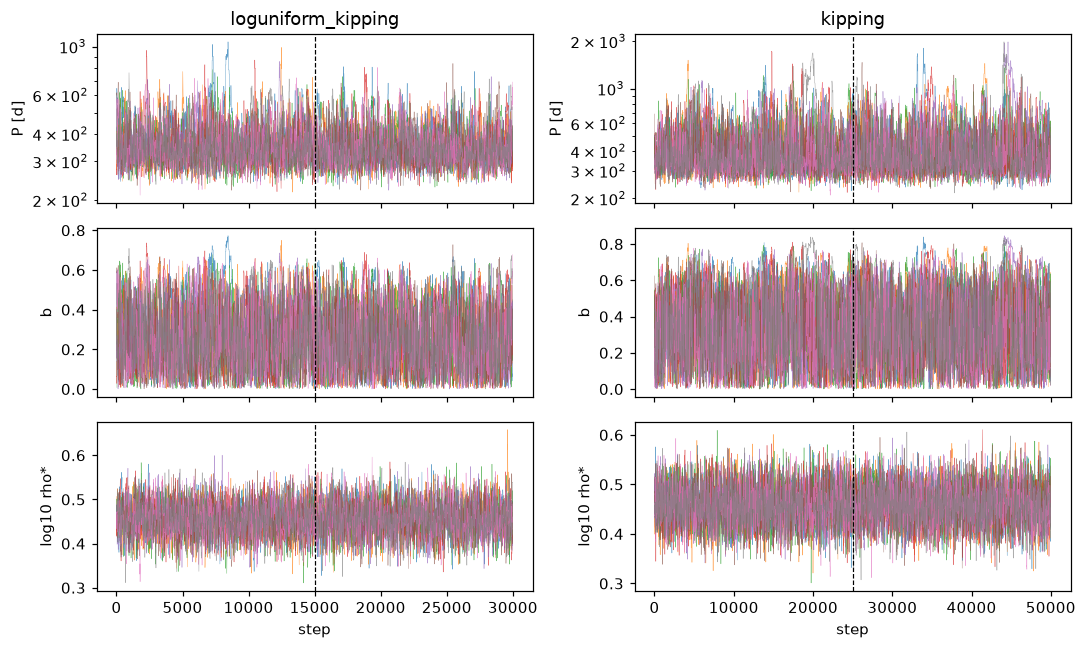

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(10, 6), sharex="col")
for j, key in enumerate(PRIORS.values()):
    ch, th = chains[key]["chain"], chains[key]["thin"]
    steps = np.arange(ch.shape[0]) * th
    for i, (name, tf) in enumerate([("P [d]", lambda c: np.exp(c[..., 1])),
                                    ("b", lambda c: c[..., 2]),
                                    ("log10 rho*", lambda c: c[..., 6])]):
        ax = axes[i, j]
        ax.plot(steps, tf(ch)[:, :8], lw=0.3, alpha=0.7)
        ax.axvline(chains[key]["n"] // 2, color="k", ls="--", lw=0.8)
        ax.set_ylabel(name)
    axes[0, j].set_title(key)
    axes[0, j].set_yscale("log")
    axes[-1, j].set_xlabel("step")
fig.tight_layout()

## 2. Posterior vs. Venner et al. (2026), Table 2

In [4]:
PAPER = {  # median, -err, +err
    "T0 (BKJD)": (3222.0969, 0.0032, 0.0035), "T14_hr": (9.76, 0.18, 0.21),
    "depth_ppm": (225, 10, 10), "k": (0.01368, 0.0004, 0.0006),
    "v_tr": (4.76, 0.65, 0.23), "P": (355, 59, 200), "a_au": (0.88, 0.10, 0.32),
    "a_over_R": (270, 37, 93), "Rp_earth": (1.06, 0.05, 0.06),
    "insolation": (0.29, 0.13, 0.11), "Teq_0.3": (188, 25, 16),
}

def summarise(x):
    q = np.percentile(x, [15.865, 50, 84.135])
    return q[1], q[1] - q[0], q[2] - q[1]

def fmt(m, lo, hi, nd):
    return f"{m:.{nd}f} -{lo:.{nd}f} +{hi:.{nd}f}"

ND = {"T0 (BKJD)": 4, "k": 5, "T14_hr": 2, "v_tr": 2, "insolation": 2, "a_au": 2, "Rp_earth": 2}
der = {}
for key in PRIORS.values():
    d = tr.derived(chains[key]["flat"], rng=1)
    d["T0 (BKJD)"] = chains[key]["flat"][:, 0]
    der[key] = d

rows = []
for p, ref in PAPER.items():
    nd = ND.get(p, 0)
    rows.append([p, fmt(*ref, nd)] + [fmt(*summarise(der[k][p]), nd) for k in PRIORS.values()])
for p in ["b"]:
    rows.append(["b (3σ upper)", "< 0.85"] +
                [f"< {np.percentile(der[k]['b'], 99.73):.2f}" for k in PRIORS.values()])

import pandas as pd
table = pd.DataFrame(rows, columns=["parameter", "paper"] + list(PRIORS)).set_index("parameter")
display(table)

for label, key in PRIORS.items():
    P = der[key]["P"]
    h, e = np.histogram(np.log(P), bins=200)
    print(f"{label}: mode of P ≈ {np.exp(e[h.argmax()] + np.diff(e)[0] / 2):.0f} d (paper ≈ 323 d)")

,paper,A: P^-8/3 (log-unif. × Kipping),B: P^-5/3 (Kipping)
parameter,,,
T0 (BKJD),3222.0969 -0.0032 +0.0035,3222.0968 -0.0028 +0.0028,3222.0967 -0.0028 +0.0029
T14_hr,9.76 -0.18 +0.21,9.74 -0.16 +0.16,9.75 -0.16 +0.18
depth_ppm,225 -10 +10,226 -9 +9,226 -9 +9
k,0.01368 -0.00040 +0.00060,0.01358 -0.00032 +0.00036,0.01372 -0.00037 +0.00056
v_tr,4.76 -0.65 +0.23,4.84 -0.33 +0.16,4.69 -0.65 +0.27
P,355 -59 +200,335 -43 +79,370 -65 +206
a_au,0.88 -0.10 +0.32,0.85 -0.07 +0.13,0.91 -0.11 +0.31
a_over_R,270 -37 +93,258 -28 +42,278 -38 +93
Rp_earth,1.06 -0.05 +0.06,1.05 -0.04 +0.04,1.06 -0.04 +0.05


A: P^-8/3 (log-unif. × Kipping): mode of P ≈ 315 d (paper ≈ 323 d)
B: P^-5/3 (Kipping): mode of P ≈ 318 d (paper ≈ 323 d)


## 3. The P–b degeneracy

The light curve constrains the duration and shape; for fixed $\rho_\*$ and $e=0$,
$T_{14}\propto P^{1/3}\sqrt{(1+k)^2-b^2}$, so larger $b$ must be compensated by a longer $P$.
The prior on $P$ is what cuts off the long-period tail.

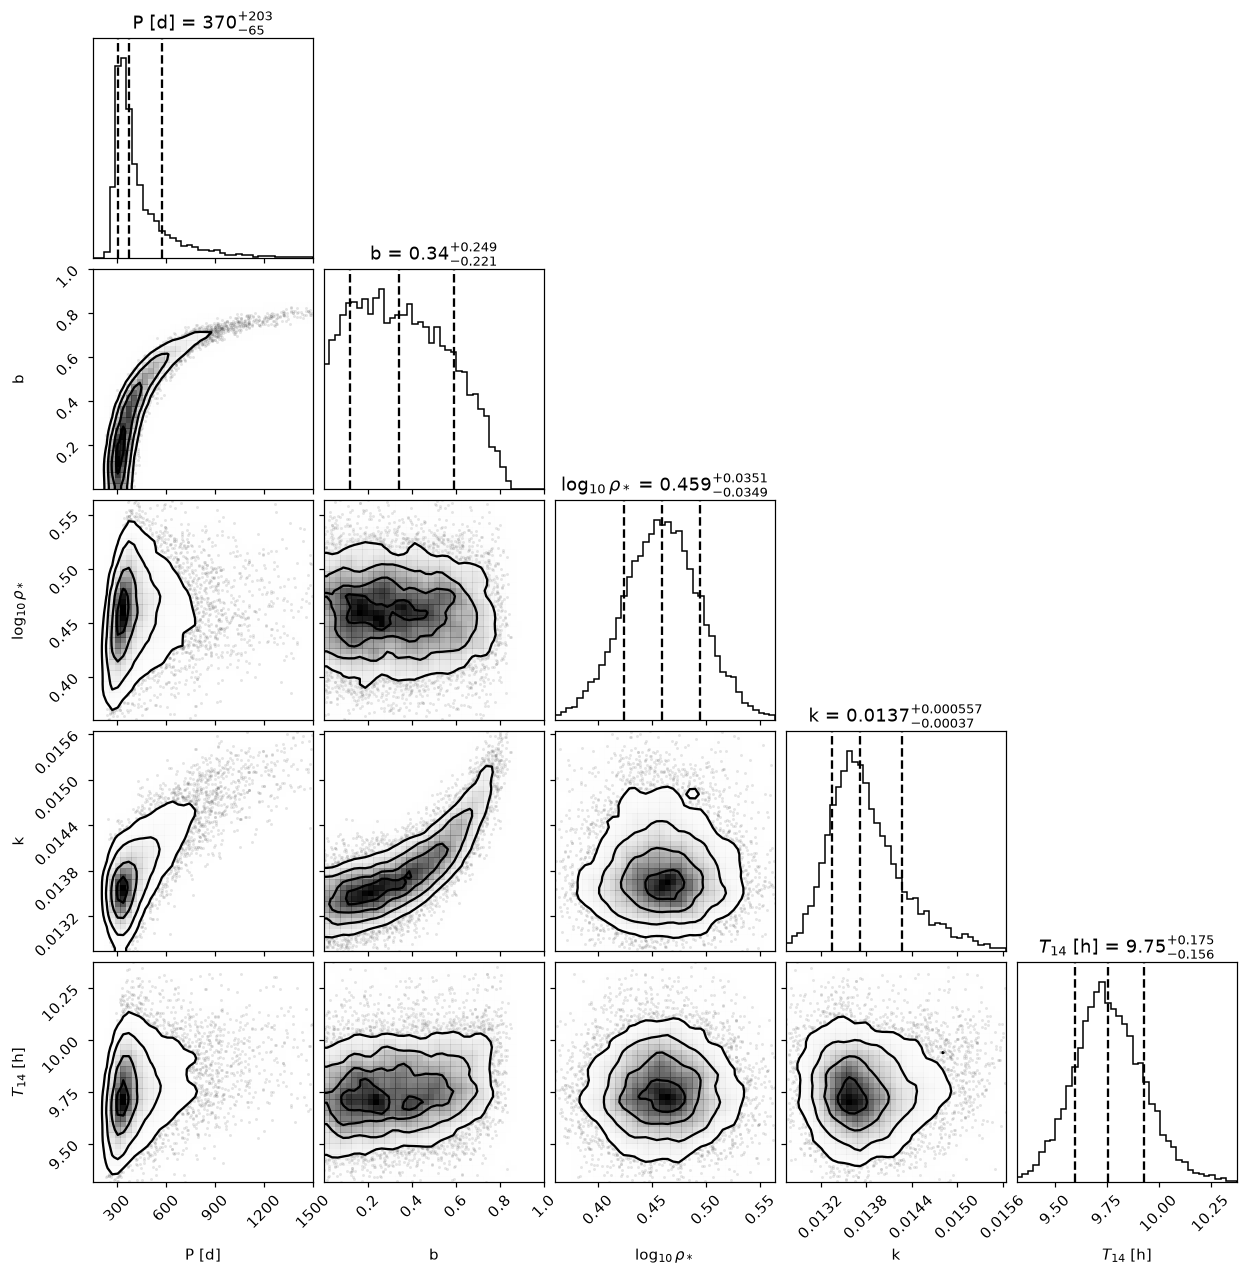

In [5]:
key = "kipping"  # variant B reproduces the paper -> reference baseline
fl = chains[key]["flat"]
d = der[key]
fig = corner.corner(np.column_stack([d["P"], d["b"], fl[:, 6], d["k"], d["T14_hr"]]),
                    labels=["P [d]", "b", r"$\log_{10}\rho_*$", "k", r"$T_{14}$ [h]"],
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".3g",
                    range=[(150, 1500), (0, 1), 0.995, 0.995, 0.995], bins=40, smooth=1)

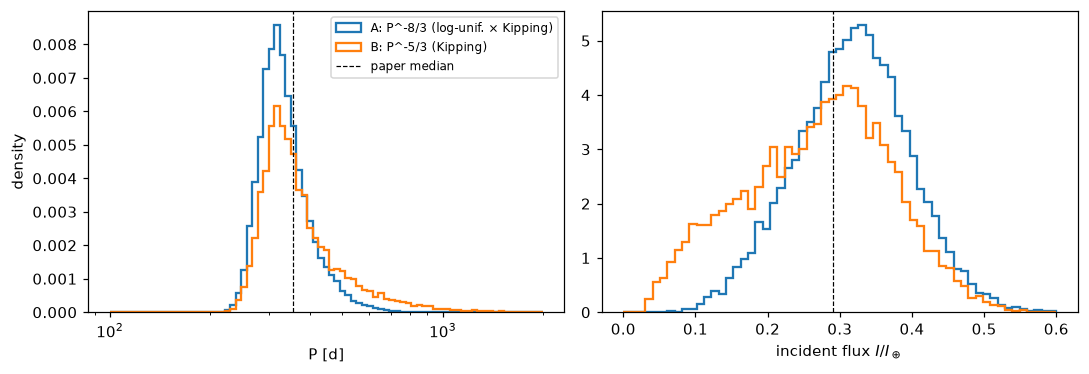

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
bins = np.geomspace(100, 2000, 80)
for label, key in PRIORS.items():
    axes[0].hist(der[key]["P"], bins=bins, density=True, histtype="step", lw=1.5, label=label)
    axes[1].hist(der[key]["insolation"], bins=np.linspace(0, 0.6, 60), density=True,
                 histtype="step", lw=1.5, label=label)
axes[0].axvline(355, color="k", ls="--", lw=0.8, label="paper median")
axes[0].set(xscale="log", xlabel="P [d]", ylabel="density")
axes[1].axvline(0.29, color="k", ls="--", lw=0.8)
axes[1].set(xlabel=r"incident flux $I/I_\oplus$")
axes[0].legend(fontsize=8)
fig.tight_layout()

## 4. Light curve and posterior predictive check

Course: *Model checking*. We draw $\theta_s$ from the posterior, simulate replicated data
$y^{\rm rep}_s = \mu(\theta_s) + \varepsilon$, $\varepsilon\sim\mathcal N(0,\sigma_s^2)$, and compare
discrepancy statistics between replicated and observed data:

* $T_1 = \chi^2(y,\theta)$ — overall fit / noise level,
* $T_2$ = lag-1 autocorrelation of the residuals — sensitivity to correlated (red) noise that a white-noise model ignores,
* $T_3$ = mean residual inside the transit — systematic misfit of the transit shape.

The posterior predictive p-value is $p_B = \Pr[T(y^{\rm rep},\theta) \ge T(y,\theta)\mid y]$.

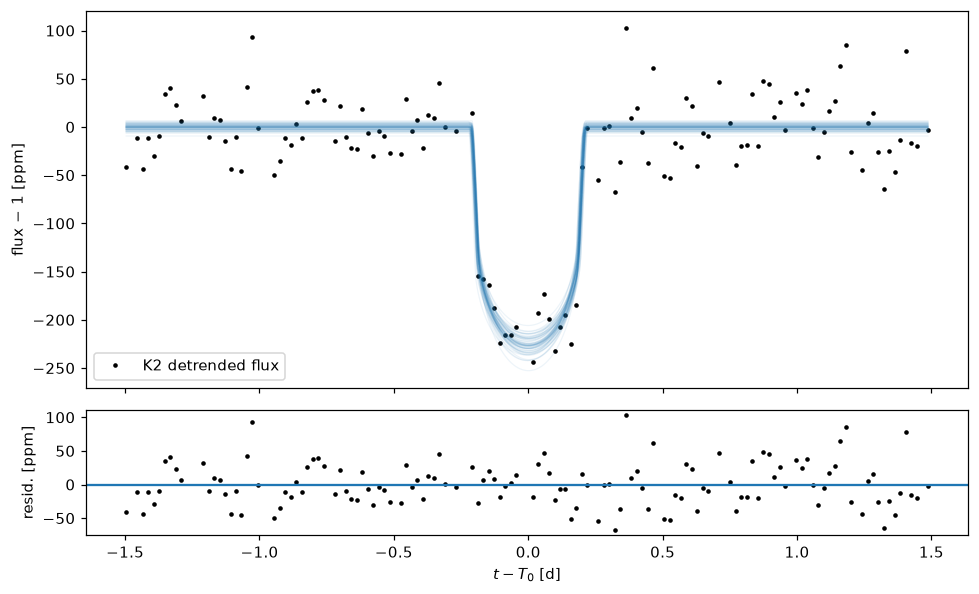

In [7]:
key = "kipping"  # variant B reproduces the paper -> reference baseline
fl = chains[key]["flat"]
m = tr.CircularTransitModel(t, f, p_min, period_prior=key)
rng = np.random.default_rng(0)
idx = rng.choice(len(fl), 2000, replace=False)
tt = np.linspace(t.min(), t.max(), 1500)

fig, (a0, a1) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, height_ratios=[3, 1])
a0.plot(t - tr.T0_GUESS, (f - 1) * 1e6, "k.", ms=4, label="K2 detrended flux")
for i in idx[:60]:
    a0.plot(tt - tr.T0_GUESS, (m.light_curve(fl[i], tt) - 1) * 1e6, "C0", alpha=0.08, lw=0.8)
resid = np.array([f - m.light_curve(fl[i]) for i in idx])
a1.plot(t - tr.T0_GUESS, np.median(resid, 0) * 1e6, "k.", ms=4)
a1.axhline(0, color="C0")
a0.set(ylabel="flux − 1 [ppm]")
a1.set(xlabel=r"$t - T_0$ [d]", ylabel="resid. [ppm]")
a0.legend()
fig.tight_layout()

$\chi^2$: p_B = 0.504
lag-1 autocorr. of residuals: p_B = 0.010
mean in-transit residual [ppm]: p_B = 0.556


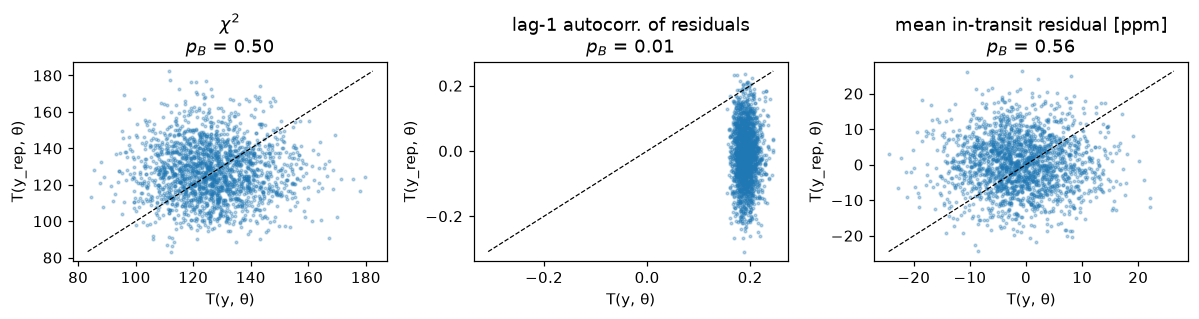

In [8]:
def stats(y, mu, sigma, in_tr):
    r = y - mu
    chi2 = np.sum((r / sigma) ** 2)
    rc = r - r.mean()
    ac1 = np.sum(rc[1:] * rc[:-1]) / np.sum(rc**2)
    return chi2, ac1, r[in_tr].mean() * 1e6

T_obs, T_rep = [], []
for i in idx:
    th = fl[i]
    mu = m.light_curve(th)
    sig = np.exp(th[-1])
    dd = tr.derived(th[None])
    in_tr = np.abs(t - th[0]) < dd["T14_hr"][0] / 48
    T_obs.append(stats(f, mu, sig, in_tr))
    T_rep.append(stats(mu + rng.normal(0, sig, len(t)), mu, sig, in_tr))
T_obs, T_rep = np.array(T_obs), np.array(T_rep)

names = [r"$\chi^2$", "lag-1 autocorr. of residuals", "mean in-transit residual [ppm]"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for j, ax in enumerate(axes):
    pB = np.mean(T_rep[:, j] >= T_obs[:, j])
    ax.scatter(T_obs[:, j], T_rep[:, j], s=3, alpha=0.3)
    lim = [min(T_obs[:, j].min(), T_rep[:, j].min()), max(T_obs[:, j].max(), T_rep[:, j].max())]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlabel=f"T(y, θ)", ylabel=f"T(y_rep, θ)", title=f"{names[j]}\n$p_B$ = {pB:.2f}")
    print(f"{names[j]}: p_B = {pB:.3f}")
fig.tight_layout()

## 5. Summary

**Reproduction.** Variant **B** ($p(P)\propto P^{-5/3}$) reproduces Table 2 of Venner et al. within
sampling noise: $P = 370^{+206}_{-65}$ d (paper $355^{+200}_{-59}$), mode ≈ 320 d (paper ≈ 323),
$T_{14}$, depth, $k$, $v_{\rm tr}$, $a$, $I$ and $b<0.82$ (3σ; paper $<0.85$) all agree.
So the paper's effective period prior is the Kipping factor $P^{-5/3}$ on top of a prior *uniform in $P$*
— the "log-uniform" in the text is the sampling coordinate, not an extra $P^{-1}$.
Variant A ($P^{-8/3}$) cuts the long-period tail (+79 d instead of +206 d) and shifts $I$ upward:
**the period prior alone already moves the result noticeably**, even at $e=0$ — a first data point
for the prior-sensitivity study.

**Convergence.** $N/\tau > 160$ for every parameter, $\hat R \le 1.01$, bulk ESS > 4000. The slowest
direction is the $P$–$b$ ridge (lnP, b, lnk); the flatter prior B mixes ~3× slower along it.
With DE moves this took $5\times10^4$ steps (~1 min) instead of the paper's $10^8$.

**Model check.** $\chi^2$ and the in-transit residual are consistent with replicated data
($p_B\approx0.5$), but the lag-1 autocorrelation of the residuals ($\approx0.2$) is never reproduced
($p_B\approx0.01$): **the noise is correlated**, which the white-noise likelihood (ours and the paper's)
ignores. This likely makes the duration — and hence $P$ — uncertainties somewhat too small.
Candidates for a fix: a GP noise model on the undetrended flux (course week 11) or at minimum
a red-noise inflation ("β factor", Pont et al. 2006).

**Next (Phase 2/3).** Use variant B as the baseline; add eccentricity priors, and treat the
period prior (A vs B) as a second sensitivity axis.

---
> **Correction (Phase 2, [03_prior_predictive.ipynb](03_prior_predictive.ipynb)).** The chains in this notebook
> under-sample the long-period / high-$b$ tail, although they pass the $\tau$ and $\hat R$ diagnostics. Nested
> sampling and a shape-space sampler agree on $P = 384^{+323}_{-79}$ d for variant B (not $370^{+206}_{-65}$),
> and $P = 347^{+150}_{-54}$ d for variant A. The *bulk* of the posterior (median, mode, $T_{14}$, depth, $R_p$,
> $I$) is unaffected. The match of variant B with the paper's Table 2 was therefore a coincidence: the authors' own posterior
> samples are reproduced by variant **A** ($P^{-8/3}$, log-uniform sampling plus the Kipping factor), correctly sampled
> (see Sec. 8 of the Phase 2 notebook). The PPC conclusion (correlated residuals) is unaffected.